In [ ]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.2/36.2 MB 25.2 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
from rdkit.Chem import AllChem
from rdkit.Chem import rdMolDescriptors
from rdkit.Chem.Draw import IPythonConsole
from rdkit.Chem import Draw
from rdkit import DataStructs
from rdkit.Chem import PandasTools
from rdkit import Chem
from rdkit.Chem import rdFMCS
import plotly.graph_objects as go

In [ ]:
# Example usage with a list of SMILES strings
smiles_list = ['COC(=O)C[C@H]1C(C)(C)[C@H](OC(C)=O)[C@]2(O)C=C3C(CC[C@]4(C)C3CC(=O)O[C@H]4c3ccoc3)[C@@]1(C)C2=O',
'COc1ccc(-c2cc(=O)c3c(O)cc(O)cc3o2)cc1',
'COc1ccc(-c2cc(=O)c3c(O)c(OC)c(O)cc3o2)cc1OC',
'COc1ccc(O[C@@H]2O[C@H](CO)[C@@H](O)[C@H](O)[C@H]2O)cc1',
'C[C@H](O)[C@@H](O)C[C@H]1OCc2c(O)cccc21',
'O=C(OC[C@H]1O[C@@H](Oc2c(-c3ccc(O)c(O)c3)oc3cc(O)cc(O)c3c2=O)[C@H](O)[C@@H](O)[C@H]1O)c1ccccc1',
'Oc1cc(O)c2c(c1)O[C@@H](c1ccc(O)c(O)c1)[C@@H](O)C2',
'O=c1c(O[C@@H]2O[C@H](CO)[C@@H](O)[C@H](O)[C@H]2O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12',
'C=C1OC(=O)[C@]2([C@H](C)C=CC(=O)[C@@H]2O)[C@H]1O',
'CN1C(=O)c2ccccc2-n2c(nc3ccccc3c2=O)[C@@H]1Cc1ccccc1',
#-------COMERCIALES---------
'Cc1ccc(cc1Cc2ccc(s2)c3ccc(cc3)F)[C@H]4[C@@H]([C@H]([C@@H]([C@H](O4)CO)O)O)O',
'Clc1ccc(cc1Cc2ccc(OCC)cc2)[C@@H]3O[C@H](CO)[C@@H](O)[C@H](O)[C@H]3O',
'C1COC[C@H]1OC2=CC=C(C=C2)CC3=C(C=CC(=C3)[C@H]4[C@@H]([C@H]([C@@H]([C@H](O4)CO)O)O)O)Cl',
'S1C(=CC2=C1C=CC=C2)CC=2C=C(C=CC2F)[C@H]2[C@H](O)[C@@H](O)[C@H](O)[C@H](O2)CO',
'CCOC1=CC=C(C=C1)CC2=CC(=C(C=C2C)OC)[C@H]3[C@@H]([C@H]([C@@H]([C@H](S3)CO)O)O)O',
'CCc1ccc(cc1)Cc2ccc3c(c2)[C@]4([C@@H]([C@H]([C@@H]([C@H](O4)CO)O)O)O)OC3.O',
'CCOC(=O)OCC1C(C(C(C(O1)Oc2ccccc2Cc3ccc(cc3)OC)O)O)O',
'OC1C(COC(=O)OCC)OC(C(O)C1O)Oc(nn(C(C)C)c2C)c2Cc3ccc(cc3)OC(C)C',
'COC1=CC=C(C=C1)C=CC2=CC(=CC(=C2)OC3C(C(C(C(O3)CO)O)O)O)O',
#'CC[C@@H](C)[C@H]1C(=O)N[C@@H]2CSSC[C@@H](C(=O)N[C@@H](CSSC[C@@H](C(=O)NCC(=O)N[C@H](C(=O)N[C@H](C(=O)N[C@H](C(=O)N[C@H](C(=O)N[C@H](C(=O)N[C@H](C(=O)N[C@H](C(=O)N[C@H](C(=O)N[C@H](C(=O)N[C@H](C(=O)N[C@@H](CSSC[C@H](NC(=O)[C@@H](NC(=O)[C@@H](NC(=O)[C@@H](NC(=O)[C@@H](NC(=O)[C@@H](NC(=O)[C@@H](NC(=O)[C@@H](NC(=O)[C@@H](NC2=O)CO)CC(C)C)CC3=CC=C(C=C3)O)CCC(=O)N)CC(C)C)CCC(=O)O)CC(=O)N)CC4=CC=C(C=C4)O)C(=O)N[C@@H](CC(=O)N)C(=O)O)C(=O)NCC(=O)N[C@@H](CCC(=O)O)C(=O)N[C@@H](CCCNC(=N)N)C(=O)NCC(=O)N[C@@H](CC5=CC=CC=C5)C(=O)N[C@@H](CC6=CC=CC=C6)C(=O)N[C@@H](CC7=CC=C(C=C7)O)C(=O)N[C@@H]([C@H](C)O)C(=O)N8CCC[C@H]8C(=O)N[C@@H](CCCCN)C(=O)N[C@@H]([C@H](C)O)C(=O)O)C(C)C)CC(C)C)CC9=CC=C(C=C9)O)CC(C)C)C)CCC(=O)O)C(C)C)CC(C)C)CC2=CNC=N2)CO)NC(=O)[C@H](CC(C)C)NC(=O)[C@H](CC2=CNC=N2)NC(=O)[C@H](CCC(=O)N)NC(=O)[C@H](C(=O)N)NC(=O)[C@H](C(C)C)NC(=O)[C@H](CC2=CC=CC=C2)N)C(=O)N[C@H](C(=O)N[C@H](C(=O)N1)CO)[C@H](C)O)NC(=O)[C@H](CCC(=O)N)NC(=O)[C@H](CCC(=O)O)NC(=O)[C@H](C(C)C)NC(=O)[C@H]([C@H](C)CC)NC(=O)CN',
'CN(C)C(=N)N=C(N)N'
               ]


#Matriz de Tanimoto

In [ ]:
from rdkit.Chem.rdFingerprintGenerator import GetMorganGenerator

# --- Using MorganGenerator (does not directly populate bitInfo) ---
# Initialize the Morgan fingerprint generator
morgan_gen = GetMorganGenerator(radius=2, fpSize=2048)

In [ ]:
# Calculate fingerprints
fps = [morgan_gen.GetFingerprint(Chem.MolFromSmiles(smi)) for smi in smiles_list]
#fps = [AllChem.MorganGenerator(Chem.MolFromSmiles(smi), 2, nBits=2048) for smi in smiles_list]
# Calculate Tanimoto similarity matrix
tanimoto_matrix = np.zeros((len(smiles_list), len(smiles_list)))
for i in range(len(smiles_list)):
    for j in range(len(smiles_list)):
        tanimoto_matrix[i, j] = DataStructs.TanimotoSimilarity(fps[i], fps[j])

#Convert to DataFrame for better visualization
tanimoto_df = pd.DataFrame(tanimoto_matrix, index=smiles_list, columns=smiles_list)
#tanimoto_df

In [ ]:
def draw_molecules(smiles_list):
    mols = [Chem.MolFromSmiles(smi) for smi in smiles_list]
    legends = [f"Molecule {i}" for i in range(0,len(mols))]
    legends.append("MCS")  # Add legend for MCS
    if any(mol is None for mol in mols):
      print("Invalid SMILES string provided in the list.")
      return None
    return Draw.MolsToGridImage(mols,legends=legends, molsPerRow=4, subImgSize=(350, 350))

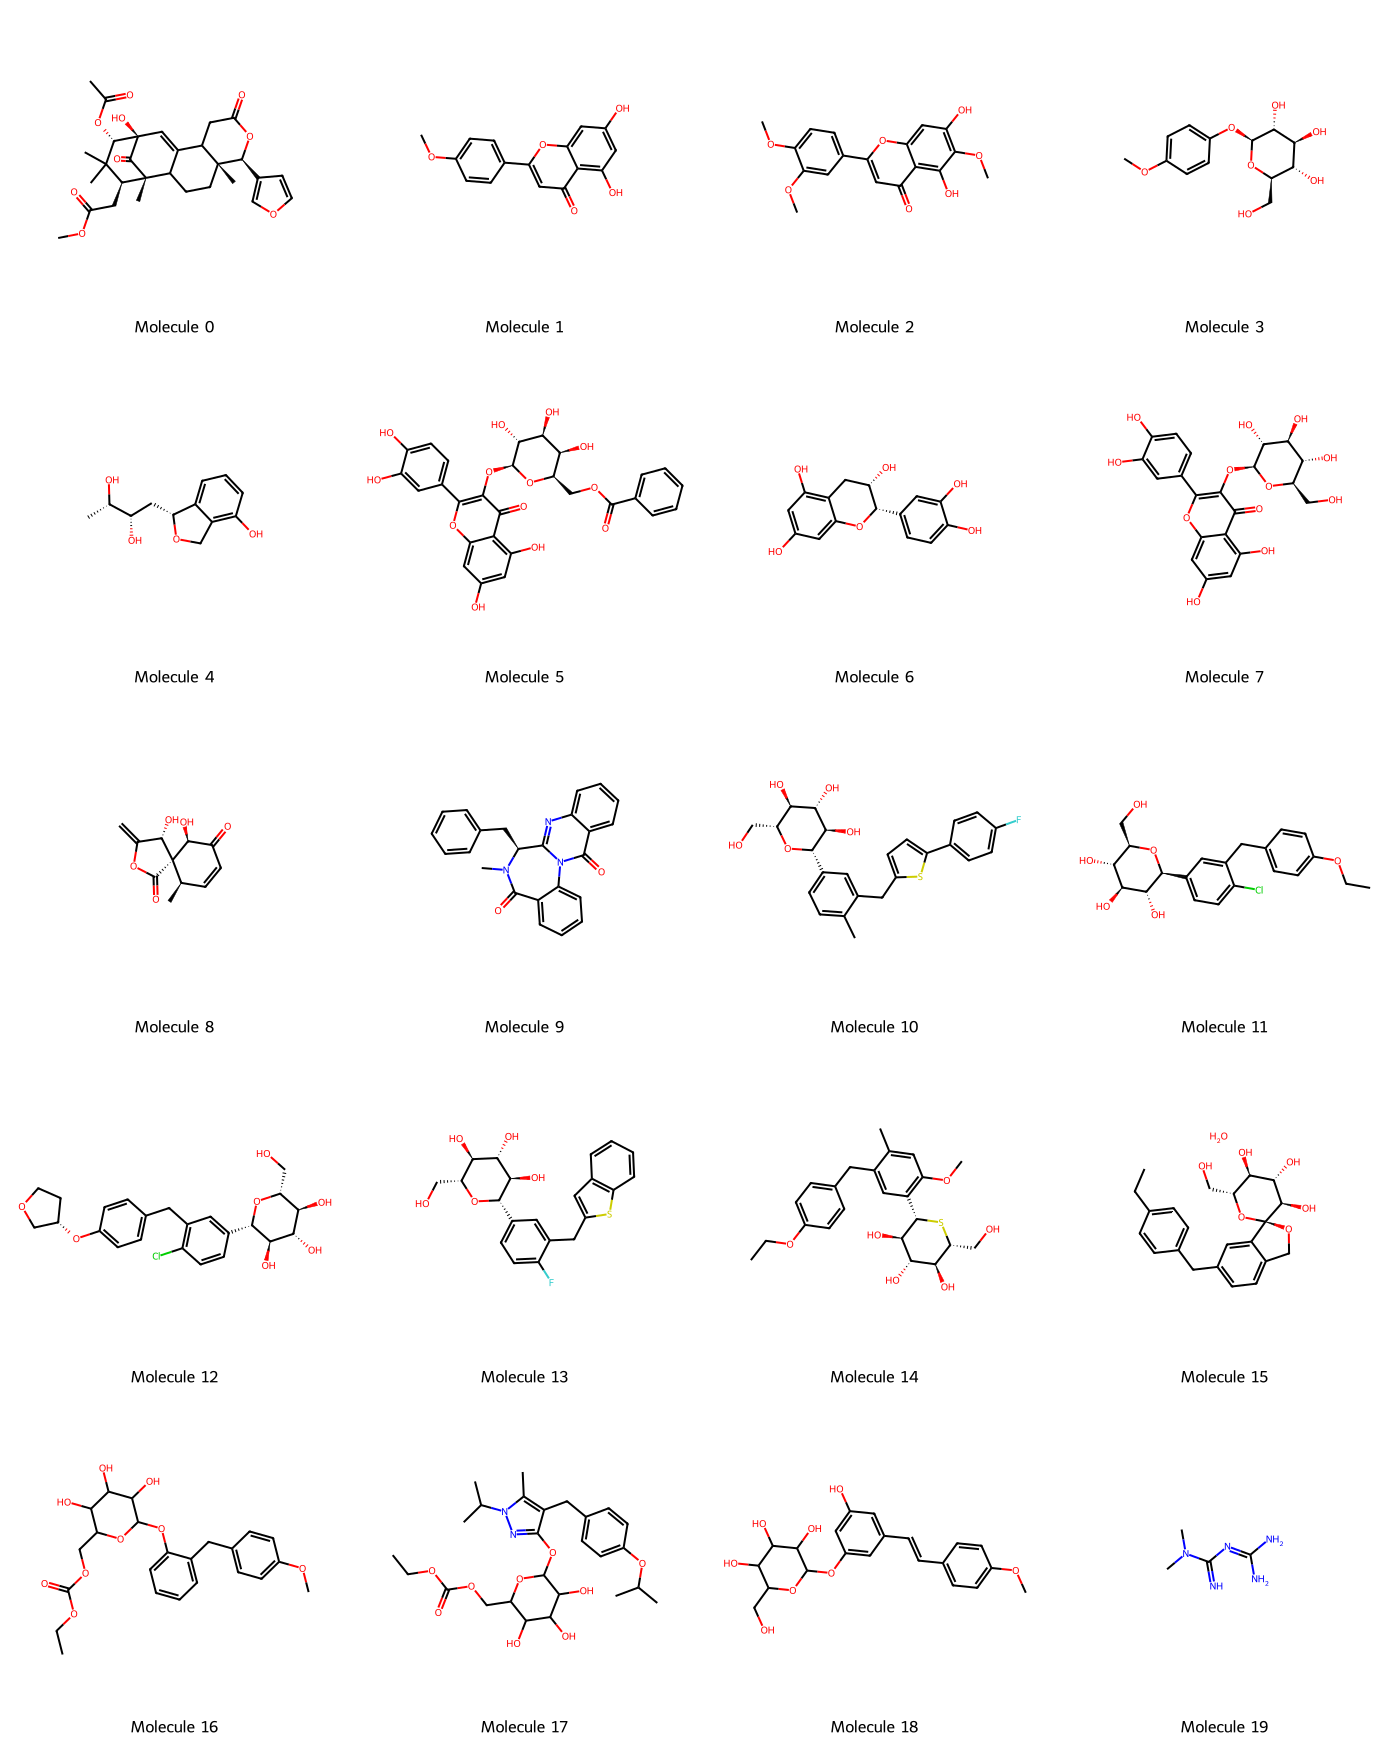

In [ ]:
# Call the function to draw the molecules
image = draw_molecules(smiles_list)
image

In [ ]:
# prompt: con tanimoto_df genera una matriz con plotly
fig = go.Figure(data=go.Heatmap(z=tanimoto_df.values,
                                colorscale='Oranges'))

fig.update_layout(title='Tanimoto Similarity Matrix',
                  xaxis_title='Molecules',
                  yaxis_title='Molecules')

fig.show()

In [ ]:
# Podemos redefinir el smiles_list para seleccionar moléculas en específico
smiles_list = [
'COC(=O)C[C@H]1C(C)(C)[C@H](OC(C)=O)[C@]2(O)C=C3C(CC[C@]4(C)C3CC(=O)O[C@H]4c3ccoc3)[C@@]1(C)C2=O',
#'COc1ccc(-c2cc(=O)c3c(O)cc(O)cc3o2)cc1',#1
#'COc1ccc(-c2cc(=O)c3c(O)c(OC)c(O)cc3o2)cc1OC' ,#2
'COc1ccc(O[C@@H]2O[C@H](CO)[C@@H](O)[C@H](O)[C@H]2O)cc1',#3
'C[C@H](O)[C@@H](O)C[C@H]1OCc2c(O)cccc21',#4
#'O=C(OC[C@H]1O[C@@H](Oc2c(-c3ccc(O)c(O)c3)oc3cc(O)cc(O)c3c2=O)[C@H](O)[C@@H](O)[C@H]1O)c1ccccc1', #5
#'Oc1cc(O)c2c(c1)O[C@@H](c1ccc(O)c(O)c1)[C@@H](O)C2',
#'O=c1c(O[C@@H]2O[C@H](CO)[C@@H](O)[C@H](O)[C@H]2O)c(-c2ccc(O)c(O)c2)oc2cc(O)cc(O)c12', #"6"
###'C=C1OC(=O)[C@]2([C@H](C)C=CC(=O)[C@@H]2O)[C@H]1O',
#'CN1C(=O)c2ccccc2-n2c(nc3ccccc3c2=O)[C@@H]1Cc1ccccc1',
#-------COMERCIALES---------
#'Cc1ccc(cc1Cc2ccc(s2)c3ccc(cc3)F)[C@H]4[C@@H]([C@H]([C@@H]([C@H](O4)CO)O)O)O',#10
#'Clc1ccc(cc1Cc2ccc(OCC)cc2)[C@@H]3O[C@H](CO)[C@@H](O)[C@H](O)[C@H]3O',
#'C1COC[C@H]1OC2=CC=C(C=C2)CC3=C(C=CC(=C3)[C@H]4[C@@H]([C@H]([C@@H]([C@H](O4)CO)O)O)O)Cl',
#'S1C(=CC2=C1C=CC=C2)CC=2C=C(C=CC2F)[C@H]2[C@H](O)[C@@H](O)[C@H](O)[C@H](O2)CO',
#'CCOC1=CC=C(C=C1)CC2=CC(=C(C=C2C)OC)[C@H]3[C@@H]([C@H]([C@@H]([C@H](S3)CO)O)O)O',
#'CCc1ccc(cc1)Cc2ccc3c(c2)[C@]4([C@@H]([C@H]([C@@H]([C@H](O4)CO)O)O)O)OC3.O',#15
#'CCOC(=O)OCC1C(C(C(C(O1)Oc2ccccc2Cc3ccc(cc3)OC)O)O)O',
#'OC1C(COC(=O)OCC)OC(C(O)C1O)Oc(nn(C(C)C)c2C)c2Cc3ccc(cc3)OC(C)C',
#'COC1=CC=C(C=C1)C=CC2=CC(=CC(=C2)OC3C(C(C(C(O3)CO)O)O)O)O',
#'CC[C@@H](C)[C@H]1C(=O)N[C@@H]2CSSC[C@@H](C(=O)N[C@@H](CSSC[C@@H](C(=O)NCC(=O)N[C@H](C(=O)N[C@H](C(=O)N[C@H](C(=O)N[C@H](C(=O)N[C@H](C(=O)N[C@H](C(=O)N[C@H](C(=O)N[C@H](C(=O)N[C@H](C(=O)N[C@H](C(=O)N[C@@H](CSSC[C@H](NC(=O)[C@@H](NC(=O)[C@@H](NC(=O)[C@@H](NC(=O)[C@@H](NC(=O)[C@@H](NC(=O)[C@@H](NC(=O)[C@@H](NC(=O)[C@@H](NC2=O)CO)CC(C)C)CC3=CC=C(C=C3)O)CCC(=O)N)CC(C)C)CCC(=O)O)CC(=O)N)CC4=CC=C(C=C4)O)C(=O)N[C@@H](CC(=O)N)C(=O)O)C(=O)NCC(=O)N[C@@H](CCC(=O)O)C(=O)N[C@@H](CCCNC(=N)N)C(=O)NCC(=O)N[C@@H](CC5=CC=CC=C5)C(=O)N[C@@H](CC6=CC=CC=C6)C(=O)N[C@@H](CC7=CC=C(C=C7)O)C(=O)N[C@@H]([C@H](C)O)C(=O)N8CCC[C@H]8C(=O)N[C@@H](CCCCN)C(=O)N[C@@H]([C@H](C)O)C(=O)O)C(C)C)CC(C)C)CC9=CC=C(C=C9)O)CC(C)C)C)CCC(=O)O)C(C)C)CC(C)C)CC2=CNC=N2)CO)NC(=O)[C@H](CC(C)C)NC(=O)[C@H](CC2=CNC=N2)NC(=O)[C@H](CCC(=O)N)NC(=O)[C@H](C(=O)N)NC(=O)[C@H](C(C)C)NC(=O)[C@H](CC2=CC=CC=C2)N)C(=O)N[C@H](C(=O)N[C@H](C(=O)N1)CO)[C@H](C)O)NC(=O)[C@H](CCC(=O)N)NC(=O)[C@H](CCC(=O)O)NC(=O)[C@H](C(C)C)NC(=O)[C@H]([C@H](C)CC)NC(=O)CN',
#'CN(C)C(=N)N=C(N)N'
               ]


#Funciones

In [ ]:
def find_mcs_multiple(smiles_list):
    mols = [Chem.MolFromSmiles(smiles) for smiles in smiles_list]
    # Check for invalid SMILES
    if any(mol is None for mol in mols):
        print("Invalid SMILES string provided in the list.")
        return None, None, 0, False

    mcs = rdFMCS.FindMCS(mols)
    mcs_mol = Chem.MolFromSmarts(mcs.smartsString)

    return mcs_mol, mcs.smartsString, mcs.numAtoms, True


In [ ]:
#Finds the MCS among multiple molecules and draws them with highlights.
def draw_multiple_mcs(smiles_list):
    mols = [Chem.MolFromSmiles(smiles) for smiles in smiles_list]
    mcs_mol, mcs_smarts, mcs_atom_count, success = find_mcs_multiple(smiles_list)

    if success:
        highlight_lists = [mol.GetSubstructMatch(mcs_mol) for mol in mols]
        legends = [f"Molecule {i+1}" for i in range(len(mols))]
        legends.append("MCS")  # Add legend for MCS
        mols.append(mcs_mol) # Add MCS to list for drawing
        highlight_lists.append([]) #No highlight for MCS itself

        img = Draw.MolsToGridImage(mols, #legends=legends,
                                   highlightAtomLists=highlight_lists, subImgSize=(450,450))
        return img
    else:
        return None

In [ ]:
comparison_image = draw_multiple_mcs(smiles_list)

if comparison_image:
    comparison_image
else:
    print("MCS not found or invalid SMILES provided.")

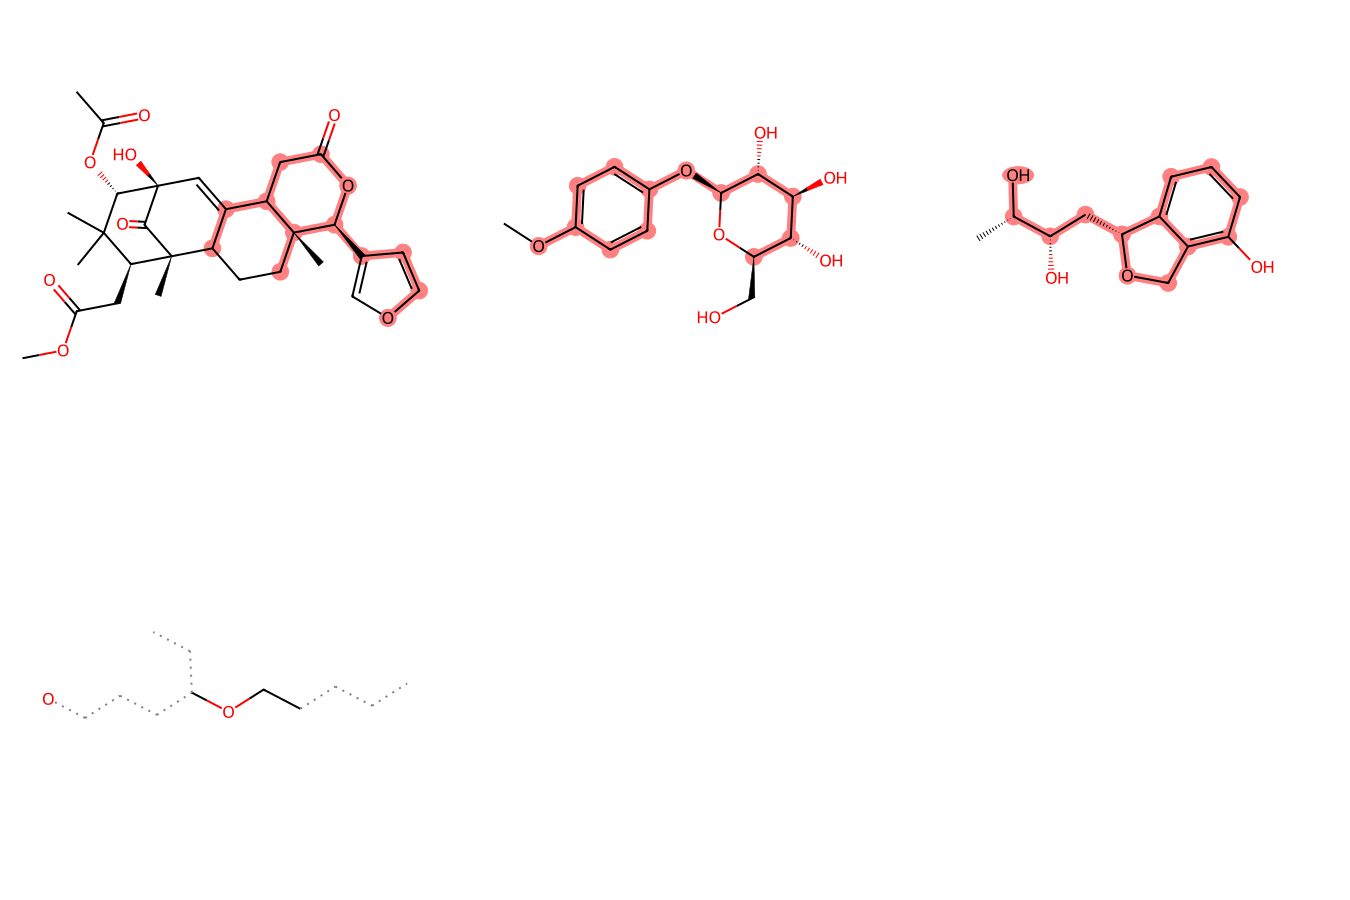

In [ ]:
comparison_image

Realizado por
Dr. Erick Correa
Maricarmen Cedillo
Enrique López
FES Zaragoza UNAM